## **MI PROYECTO EDA**

**Hipótesis:** Los equipos de la Premier League obtienen mejores resultados cuando juegan como locales, que cuando juegan como visitantes

Preguntas que investigar:
- ¿Se ganan más partidos jugando en casa?
- ¿Se marcan más goles como local?
- ¿Se realizan más tiros a puerta?
- ¿Se consiguen más córneres?
- ¿Ha disminuido la ventaja de jugar en casa con el paso de los años?

## Fuentes de datos

**Fuente:** archivo `results.csv` con los partidos de la Premier League desde la temporada 1993-94 hasta la 2021-22.
*<<COMPLETAR: enlace de donde descargué el archivo y su licencia>>*

- **Datos necesarios (requerimientos):** resultado de cada partido, equipos local y visitante, y estadísticas del partido (tiros, córneres, tarjetas) en varias temporadas.
- **Disponibilidad:** el archivo es público y se puede descargar sin coste.
- **Tamaño:** 11.113 partidos y 23 columnas, repartidos en 29 temporadas.

### Tabla de variables

| Columna | Qué representa | Tipo | Uso en el análisis |
|---|---|---|---|
| `Season` | Temporada (por ejemplo 2015-16) | texto | Agrupar partidos y estudiar la evolución |
| `DateTime` | Fecha y hora del partido (UTC) | fecha | Ordenar los partidos |
| `HomeTeam` | Equipo local | texto | Identificar al equipo que juega en casa |
| `AwayTeam` | Equipo visitante | texto | Identificar al equipo que juega fuera |
| `FTHG` | Goles del local al final del partido | entero | Pregunta 2 |
| `FTAG` | Goles del visitante al final del partido | entero | Pregunta 2 |
| `FTR` | Resultado final: H = gana el local, D = empate, A = gana el visitante | categórica | Variable principal (pregunta 1) |
| `HTHG` | Goles del local al descanso | entero | Contexto |
| `HTAG` | Goles del visitante al descanso | entero | Contexto |
| `HTR` | Resultado al descanso (H, D o A) | categórica | Contexto |
| `Referee` | Árbitro del partido | texto | No se usa (demasiadas categorías) |
| `HS` | Tiros del local | entero | Estadísticas del partido |
| `AS` | Tiros del visitante | entero | Estadísticas del partido |
| `HST` | Tiros a puerta del local | entero | Pregunta 3 |
| `AST` | Tiros a puerta del visitante | entero | Pregunta 3 |
| `HC` | Córneres del local | entero | Pregunta 4 |
| `AC` | Córneres del visitante | entero | Pregunta 4 |
| `HF` | Faltas cometidas por el local | entero | Estadísticas del partido |
| `AF` | Faltas cometidas por el visitante | entero | Estadísticas del partido |
| `HY` | Tarjetas amarillas del local | entero | Estadísticas del partido |
| `AY` | Tarjetas amarillas del visitante | entero | Estadísticas del partido |
| `HR` | Tarjetas rojas del local | entero | Estadísticas del partido |
| `AR` | Tarjetas rojas del visitante | entero | Estadísticas del partido |

Cargo el archivo y miro su forma:

## Calidad de los datos y limpieza

### Valores nulos

Empiezo viendo cuántos nulos hay en cada columna.

In [69]:
import pandas as pd
import numpy as np
from bootcampviztools import *
import matplotlib.pyplot as plt 
import seaborn as sns
from scipy import stats


In [50]:
pip install jinja2

  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
Using cached jinja2-3.1.6-py3-none-any.whl (134 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [jinja2]2m1/2 [jinja2]

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [24]:
df_partidos = pd.read_csv("results.csv", encoding="cp1252")

df_partidos

,Season,DateTime,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,HTR,...,HST,AST,HC,AC,HF,AF,HY,AY,HR,AR
0,1993-94,1993-08-14T00:00:00Z,Arsenal,Coventry,0,3,A,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1993-94,1993-08-14T00:00:00Z,Aston Villa,QPR,4,1,H,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1993-94,1993-08-14T00:00:00Z,Chelsea,Blackburn,1,2,A,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1993-94,1993-08-14T00:00:00Z,Liverpool,Sheffield Weds,2,0,H,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1993-94,1993-08-14T00:00:00Z,Man City,Leeds,1,1,D,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11108,2021-22,2022-04-09T17:30:00Z,Aston Villa,Tottenham,0,4,A,0.0,1.0,A,...,8.0,5.0,9.0,3.0,12.0,14.0,2.0,3.0,0.0,0.0
11109,2021-22,2022-04-10T14:00:00Z,Brentford,West Ham,2,0,H,0.0,0.0,D,...,7.0,1.0,4.0,6.0,2.0,6.0,0.0,1.0,0.0,0.0
11110,2021-22,2022-04-10T14:00:00Z,Leicester,Crystal Palace,2,1,H,2.0,0.0,H,...,3.0,3.0,3.0,4.0,11.0,12.0,1.0,1.0,0.0,0.0
11111,2021-22,2022-04-10T14:00:00Z,Norwich,Burnley,2,0,H,1.0,0.0,H,...,6.0,4.0,6.0,7.0,12.0,10.0,1.0,1.0,0.0,0.0


In [25]:
df_partidos.isna().all()

Season      False
DateTime    False
HomeTeam    False
AwayTeam    False
FTHG        False
FTAG        False
FTR         False
HTHG        False
HTAG        False
HTR         False
Referee     False
HS          False
AS          False
HST         False
AST         False
HC          False
AC          False
HF          False
AF          False
HY          False
AY          False
HR          False
AR          False
dtype: bool

In [26]:
df_partidos.isna().sum().sort_values(ascending=False)

AC          2824
HF          2824
AST         2824
HS          2824
AS          2824
HST         2824
Referee     2824
HY          2824
AY          2824
HR          2824
AF          2824
AR          2824
HC          2824
HTR          924
HTAG         924
HTHG         924
FTR            0
FTHG           0
FTAG           0
HomeTeam       0
DateTime       0
Season         0
AwayTeam       0
dtype: int64

In [27]:
df_partidos.isna().sum(axis=1).value_counts().sort_index()

0     8289
13    1900
16     924
Name: count, dtype: int64

In [28]:
#Selecciono columna de stats y comprubo los Na's que tienen, para ver si coinciden que faltan en todas las columnas de la misma fila

columnas_stats = [
    "HS", "AS", "HST", "AST",
    "HC", "AC", "HF", "AF",
    "HY", "AY", "HR", "AR"
]

df_partidos[columnas_stats].isna().sum(axis=1).value_counts()

0     8289
12    2824
Name: count, dtype: int64

In [29]:
#Selecciono las columnas principales y creo un nuevo dataframe (mediante una copia de original) que contiene las columnas principales sin Na's
columnas_principales = [
    "Season", "DateTime", "HomeTeam",
    "AwayTeam", "FTHG", "FTAG", "FTR"
]

df_clean = df_partidos.dropna(
    subset=columnas_principales
).copy()

In [30]:
df_clean

,Season,DateTime,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,HTR,...,HST,AST,HC,AC,HF,AF,HY,AY,HR,AR
0,1993-94,1993-08-14T00:00:00Z,Arsenal,Coventry,0,3,A,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1993-94,1993-08-14T00:00:00Z,Aston Villa,QPR,4,1,H,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1993-94,1993-08-14T00:00:00Z,Chelsea,Blackburn,1,2,A,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1993-94,1993-08-14T00:00:00Z,Liverpool,Sheffield Weds,2,0,H,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1993-94,1993-08-14T00:00:00Z,Man City,Leeds,1,1,D,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11108,2021-22,2022-04-09T17:30:00Z,Aston Villa,Tottenham,0,4,A,0.0,1.0,A,...,8.0,5.0,9.0,3.0,12.0,14.0,2.0,3.0,0.0,0.0
11109,2021-22,2022-04-10T14:00:00Z,Brentford,West Ham,2,0,H,0.0,0.0,D,...,7.0,1.0,4.0,6.0,2.0,6.0,0.0,1.0,0.0,0.0
11110,2021-22,2022-04-10T14:00:00Z,Leicester,Crystal Palace,2,1,H,2.0,0.0,H,...,3.0,3.0,3.0,4.0,11.0,12.0,1.0,1.0,0.0,0.0
11111,2021-22,2022-04-10T14:00:00Z,Norwich,Burnley,2,0,H,1.0,0.0,H,...,6.0,4.0,6.0,7.0,12.0,10.0,1.0,1.0,0.0,0.0


In [31]:
#La columna de DateTime, lo convierto en fecha normal
df_clean["DateTime"] = pd.to_datetime(
    df_clean["DateTime"],
    errors="coerce",
    dayfirst=True)

/var/folders/qf/6_5j_2l51z13bt0rbmpg__q80000gp/T/ipykernel_1693/1861124337.py:2: UserWarning: Parsing dates in %Y-%m-%dT%H:%M:%S%z format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  df_clean["DateTime"] = pd.to_datetime(


In [32]:
df_clean = df_clean.dropna(subset=["DateTime"])

In [33]:
df_clean.duplicated().sum()

np.int64(0)

In [34]:
df_clean = df_clean.drop_duplicates()

In [35]:
#Hago un dataframe nuevo con las columnas de estadísticas sin Na's
df_stats = df_clean.dropna(
    subset=columnas_stats
).copy()

In [36]:
#Cojo una muestra de 2000 partidos para mi EDA, lo hago agrupando por season, de esta manera tendre el mismo porcentaje de partidos por season en el df_muestra
df_muestra = (
    df_stats.groupby("Season")
    .sample(frac=2000 / len(df_stats), random_state=42)
    .sort_values("DateTime")
    .reset_index(drop=True)
)

df_muestra = df_muestra.sort_values("Season").reset_index(drop=True)

In [37]:
df_muestra

,Season,DateTime,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,HTR,...,HST,AST,HC,AC,HF,AF,HY,AY,HR,AR
0,2000-01,2000-08-19 00:00:00+00:00,Derby,Southampton,2,2,D,1.0,2.0,A,...,4.0,6.0,5.0,8.0,11.0,13.0,1.0,1.0,0.0,0.0
1,2000-01,2001-02-10 00:00:00+00:00,Southampton,Bradford,2,0,H,0.0,0.0,D,...,6.0,1.0,8.0,0.0,9.0,16.0,0.0,1.0,0.0,0.0
2,2000-01,2001-02-10 00:00:00+00:00,Sunderland,Liverpool,1,1,D,0.0,0.0,D,...,6.0,4.0,9.0,6.0,15.0,25.0,5.0,3.0,0.0,0.0
3,2000-01,2001-02-03 00:00:00+00:00,Liverpool,West Ham,3,0,H,2.0,0.0,H,...,10.0,3.0,5.0,3.0,9.0,6.0,0.0,1.0,0.0,1.0
4,2000-01,2001-02-03 00:00:00+00:00,Bradford,Aston Villa,0,3,A,0.0,0.0,D,...,2.0,6.0,3.0,4.0,14.0,14.0,2.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2002,2021-22,2021-10-30 12:30:00+00:00,Leicester,Arsenal,0,2,A,0.0,2.0,A,...,8.0,5.0,7.0,6.0,8.0,11.0,2.0,0.0,0.0,0.0
2003,2021-22,2021-10-24 16:30:00+00:00,Man United,Liverpool,0,5,A,0.0,4.0,A,...,4.0,8.0,6.0,3.0,10.0,8.0,6.0,0.0,1.0,0.0
2004,2021-22,2021-10-23 17:30:00+00:00,Brighton,Man City,1,4,A,0.0,3.0,A,...,5.0,14.0,7.0,6.0,10.0,6.0,2.0,3.0,0.0,0.0
2005,2021-22,2021-11-06 15:00:00+00:00,Crystal Palace,Wolves,2,0,H,0.0,0.0,D,...,6.0,2.0,4.0,6.0,14.0,13.0,2.0,1.0,0.0,0.0


In [38]:
print("Partidos seleccionados:", len(df_muestra))

Partidos seleccionados: 2007


In [39]:
df_muestra.isna().sum().sort_values(ascending=False)

Season      0
DateTime    0
HomeTeam    0
AwayTeam    0
FTHG        0
FTAG        0
FTR         0
HTHG        0
HTAG        0
HTR         0
Referee     0
HS          0
AS          0
HST         0
AST         0
HC          0
AC          0
HF          0
AF          0
HY          0
AY          0
HR          0
AR          0
dtype: int64

In [40]:
print("Partidos seleccionados:", len(df_muestra))

print(df_muestra["Season"].value_counts().sort_index())

Partidos seleccionados: 2007
Season
2000-01    92
2001-02    92
2002-03    92
2003-04    92
2004-05    92
2005-06    92
2006-07    92
2007-08    92
2008-09    92
2009-10    92
2010-11    92
2011-12    92
2012-13    92
2013-14    92
2014-15    92
2015-16    92
2016-17    92
2017-18    92
2018-19    92
2019-20    92
2020-21    92
2021-22    75
Name: count, dtype: int64


Hay 2.824 partidos con las estadísticas vacías. Compruebo si faltan todas a la vez o por separado:

In [41]:
columnas_stats = ["HS", "AS", "HST", "AST", "HC", "AC", "HF", "AF", "HY", "AY", "HR", "AR"]

# Número de estadísticas que faltan en cada partido
df_partidos[columnas_stats].isna().sum(axis=1).value_counts()

0     8289
12    2824
Name: count, dtype: int64

#### **EMPEZAMOS CON EL ANÁLISIS**


Comprombamos el tipo de cada variable

In [42]:
#Analizamos de que tipo es cada variable
def card_tipo(df,umbral_categoria = 10, umbral_continua = 30):
    # Primera parte: Preparo el dataset con cardinalidades, % variación cardinalidad, y tipos
    df_temp = pd.DataFrame([df.nunique(), df.nunique()/len(df) * 100, df.dtypes]) # Cardinaliad y porcentaje de variación de cardinalidad
    df_temp = df_temp.T # Como nos da los valores de las columnas en columnas, y quiero que estas sean filas, la traspongo
    df_temp = df_temp.rename(columns = {0: "Card", 1: "%_Card", 2: "Tipo"}) # Cambio el nombre de la transposición anterior para que tengan más sentido, y uso asignación en vez de inplace = True (esto es arbitrario para el tamaño de este dataset)

    # Corrección para cuando solo tengo un valor
    df_temp.loc[df_temp.Card == 1, "%_Card"] = 0.00

    # Creo la columna de sugerenica de tipo de variable, empiezo considerando todas categóricas pero podría haber empezado por cualquiera, siempre que adapte los filtros siguientes de forma correspondiente
    df_temp["tipo_sugerido"] = "Categorica"
    df_temp.loc[df_temp["Card"] == 2, "tipo_sugerido"] = "Binaria"
    df_temp.loc[df_temp["Card"] >= umbral_categoria, "tipo_sugerido"] = "Numerica discreta"
    df_temp.loc[df_temp["%_Card"] >= umbral_continua, "tipo_sugerido"] = "Numerica continua"
    # Ojo los filtros aplicados cumplen con el enunciado pero no siguen su orden y planteamiento

    return df_temp

card_tipo(df_muestra)

,Card,%_Card,Tipo,tipo_sugerido
Season,22,1.096163,str,Numerica discreta
DateTime,1287,64.125561,"datetime64[us, UTC]",Numerica continua
HomeTeam,44,2.192327,str,Numerica discreta
AwayTeam,44,2.192327,str,Numerica discreta
FTHG,9,0.44843,int64,Categorica
FTAG,8,0.398605,int64,Categorica
FTR,3,0.149477,str,Categorica
HTHG,6,0.298954,float64,Categorica
HTAG,6,0.298954,float64,Categorica
HTR,3,0.149477,str,Categorica


### Nuevas variables

Creo columnas derivadas que facilitan responder a las preguntas. Las diferencias se calculan siempre como **local − visitante**:
un valor positivo significa que el local ha tenido más.

In [43]:
df = df_muestra.copy()

# Año en que empieza la temporada: "2000-01" -> 2000
df["año_inicio"] = df["Season"].str[:4].astype(int)

# Resultados en texto legible (H = Home, D = Draw, A = Away)
df["Resultado"] = df["FTR"].map({"H": "Local", "D": "Empate", "A": "Visitante"})
df["Resultado_descanso"] = df["HTR"].map({"H": "Local", "D": "Empate", "A": "Visitante"})

# Indicadores 0/1 para poder calcular porcentajes con la media
df["Local_gana"] = (df["FTR"] == "H").astype(int)
df["Empate"] = (df["FTR"] == "D").astype(int)
df["Visitante_gana"] = (df["FTR"] == "A").astype(int)

# Diferencias local - visitante
df["dif_goles"] = df["FTHG"] - df["FTAG"]
df["dif_tiros"] = df["HS"] - df["AS"]
df["dif_tiros_puerta"] = df["HST"] - df["AST"]
df["dif_corners"] = df["HC"] - df["AC"]
df["dif_faltas"] = df["HF"] - df["AF"]
df["dif_amarillas"] = df["HY"] - df["AY"]
df["goles_totales"] = df["FTHG"] + df["FTAG"]

# Periodos de temporadas para agrupar (con 92 partidos por temporada, las temporadas sueltas son muy ruidosas)
df["Periodo"] = pd.cut(df["año_inicio"], bins=[1999, 2006, 2013, 2021],
                       labels=["2000-2006", "2007-2013", "2014-2021"]).astype(str)

df[["Season", "Resultado", "dif_goles", "dif_tiros_puerta", "dif_corners", "Periodo"]].head()

df

,Season,DateTime,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,HTR,...,Empate,Visitante_gana,dif_goles,dif_tiros,dif_tiros_puerta,dif_corners,dif_faltas,dif_amarillas,goles_totales,Periodo
0,2000-01,2000-08-19 00:00:00+00:00,Derby,Southampton,2,2,D,1.0,2.0,A,...,1,0,0,-7.0,-2.0,-3.0,-2.0,0.0,4,2000-2006
1,2000-01,2001-02-10 00:00:00+00:00,Southampton,Bradford,2,0,H,0.0,0.0,D,...,0,0,2,8.0,5.0,8.0,-7.0,-1.0,2,2000-2006
2,2000-01,2001-02-10 00:00:00+00:00,Sunderland,Liverpool,1,1,D,0.0,0.0,D,...,1,0,0,1.0,2.0,3.0,-10.0,2.0,2,2000-2006
3,2000-01,2001-02-03 00:00:00+00:00,Liverpool,West Ham,3,0,H,2.0,0.0,H,...,0,0,3,6.0,7.0,2.0,3.0,-1.0,3,2000-2006
4,2000-01,2001-02-03 00:00:00+00:00,Bradford,Aston Villa,0,3,A,0.0,0.0,D,...,0,1,-3,-4.0,-4.0,-1.0,0.0,2.0,3,2000-2006
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2002,2021-22,2021-10-30 12:30:00+00:00,Leicester,Arsenal,0,2,A,0.0,2.0,A,...,0,1,-2,7.0,3.0,1.0,-3.0,2.0,2,2014-2021
2003,2021-22,2021-10-24 16:30:00+00:00,Man United,Liverpool,0,5,A,0.0,4.0,A,...,0,1,-5,-7.0,-4.0,3.0,2.0,6.0,5,2014-2021
2004,2021-22,2021-10-23 17:30:00+00:00,Brighton,Man City,1,4,A,0.0,3.0,A,...,0,1,-3,-13.0,-9.0,1.0,4.0,-1.0,5,2014-2021
2005,2021-22,2021-11-06 15:00:00+00:00,Crystal Palace,Wolves,2,0,H,0.0,0.0,D,...,0,0,2,9.0,4.0,-2.0,1.0,1.0,2,2014-2021


In [44]:
df["HT"] = df["HY"] + df["HR"]
df["AT"] = df["AY"] + df["AR"]

## ANÁLISIS UNIVARIANTE

Comparamos entre local y visitante la media de diferentes valores que nos puede ser intereasantes para nuestro análisis de datos

In [51]:
tabla = pd.DataFrame({
    "Estadística": ["Goles", "Tiros", "Tiros a puerta", "Córners", "Faltas", "Amarillas", "Rojas", "Tarjetas totales"],
    "Local": [df["FTHG"].mean(), df["HS"].mean(), df["HST"].mean(), df["HC"].mean(),
              df["HF"].mean(), df["HY"].mean(), df["HR"].mean(), df["HT"].mean()],
    "Visitante": [df["FTAG"].mean(), df["AS"].mean(), df["AST"].mean(), df["AC"].mean(),
                  df["AF"].mean(), df["AY"].mean(), df["AR"].mean(), df["AT"].mean()],
})

tabla["Diferencia"] = tabla["Local"] - tabla["Visitante"]
tabla["Diferencia %"] = (tabla["Local"] - tabla["Visitante"]) / tabla["Visitante"] * 100

tabla_bonita = (
    tabla.set_index("Estadística")
    .style
    .format({"Local": "{:.2f}", "Visitante": "{:.2f}", "Diferencia": "{:+.2f}", "Diferencia %": "{:+.1f} %"})
    .background_gradient(subset=["Diferencia %"], cmap="RdYlGn", vmin=-40, vmax=40)
    .set_caption("Local frente a visitante: media por partido")
)

tabla_bonita

,Local,Visitante,Diferencia,Diferencia %
Estadística,,,,
Goles,1.48,1.16,+0.32,+27.8 %
Tiros,13.36,10.75,+2.61,+24.3 %
Tiros a puerta,6.05,4.87,+1.17,+24.0 %
Córners,6.12,4.84,+1.28,+26.4 %
Faltas,11.37,11.80,-0.43,-3.7 %
Amarillas,1.39,1.73,-0.34,-19.9 %
Rojas,0.06,0.10,-0.04,-40.2 %
Tarjetas totales,1.45,1.83,-0.38,-21.0 %


In [45]:
tabla = pd.DataFrame({
    "Estadística": ["Tiros", "Tiros a puerta", "Córners", "Amarillas", "Rojas", "Tarjetas totales"],
    "Local": [df["HS"].mean(), df["HST"].mean(), df["HC"].mean(), df["HY"].mean(), df["HR"].mean(), df["HT"].mean()],
    "Visitante": [df["AS"].mean(), df["AST"].mean(), df["AC"].mean(), df["AY"].mean(), df["AR"].mean(), df["AT"].mean()],
})

tabla["Diferencia"] = tabla["Local"] - tabla["Visitante"]
tabla.round(2)
tabla["Diferencia %"] = (tabla["Local"] - tabla["Visitante"]) / tabla["Visitante"] * 100
tabla.round(2)

,Estadística,Local,Visitante,Diferencia,Diferencia %
0,Tiros,13.36,10.75,2.61,24.30
1,Tiros a puerta,6.05,4.87,1.17,24.02
2,Córners,6.12,4.84,1.28,26.42
3,Amarillas,1.39,1.73,-0.34,-19.86
4,Rojas,0.06,0.10,-0.04,-40.20
5,Tarjetas totales,1.45,1.83,-0.38,-20.96


In [46]:
tabla_bonita = tabla.set_index("Estadística")

In [47]:
tabla_bonita.round(2)

,Local,Visitante,Diferencia,Diferencia %
Estadística,,,,
Tiros,13.36,10.75,2.61,24.30
Tiros a puerta,6.05,4.87,1.17,24.02
Córners,6.12,4.84,1.28,26.42
Amarillas,1.39,1.73,-0.34,-19.86
Rojas,0.06,0.10,-0.04,-40.20
Tarjetas totales,1.45,1.83,-0.38,-20.96


### RESULTADOS POR PARTIDO (DESCANSO Y FINAL)

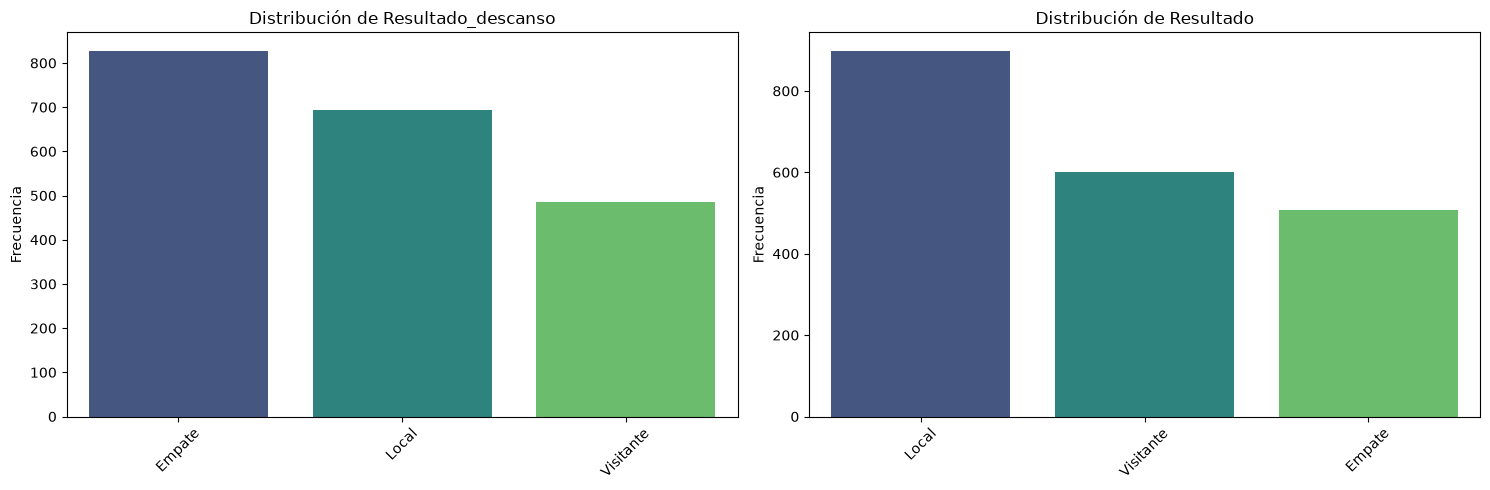

In [48]:
pinta_distribucion_categoricas(df,["Resultado_descanso","Resultado"])

El equipo local gana el **44,8 %** de los partidos, el visitante el **29,9 %** y el 25,3 % acaban en empate.

Al descanso lo más habitual es ir empatando (41,3 %), y aun así el local va por delante más veces (34,5 %) que el visitante (24,2 %).


### Variables numéricas: Goles, tiros a puerta y córneres

Miro cada estadística del local y del visitante con su histograma y su diagrama de caja.

(2, 2)


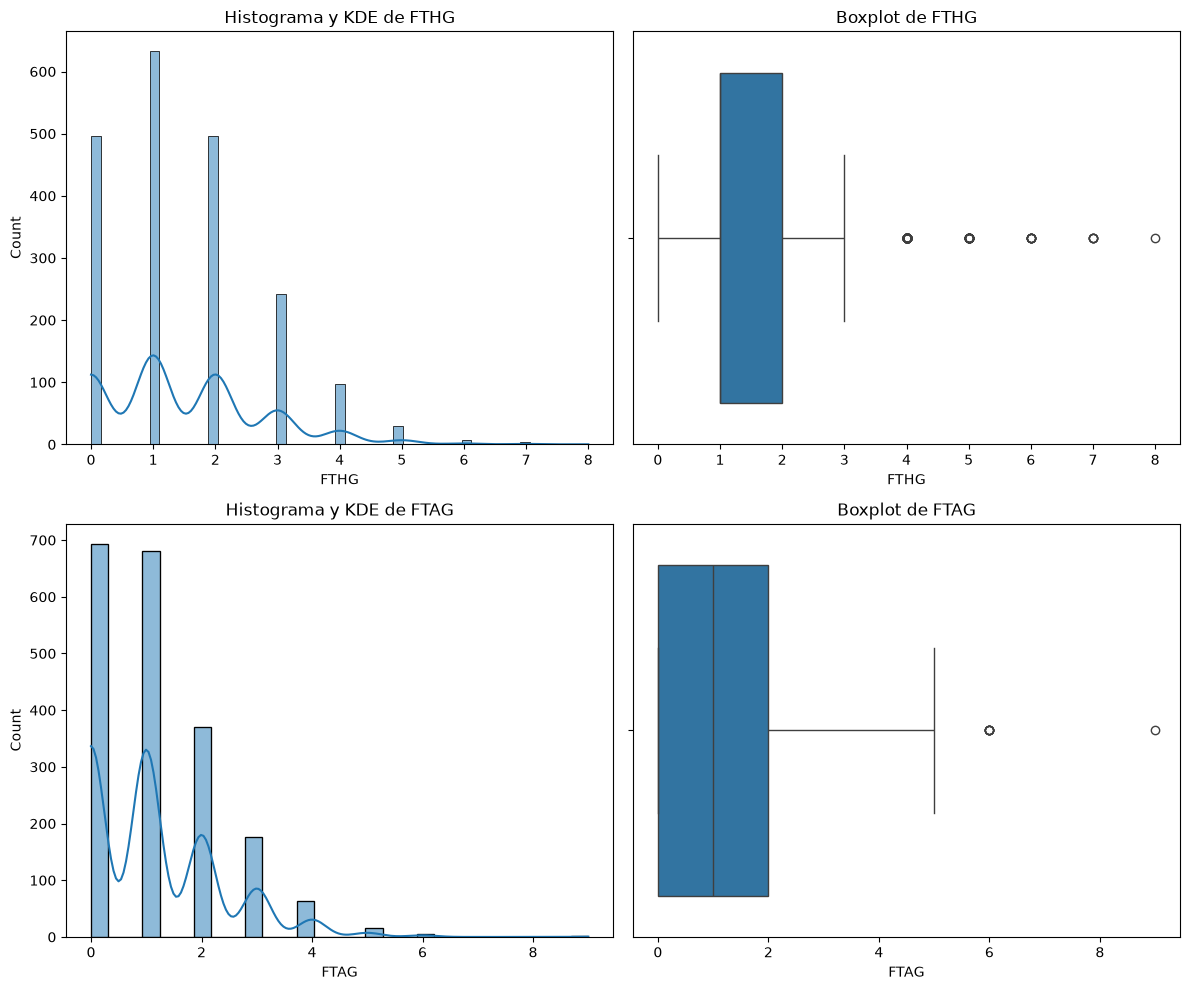

(2, 2)


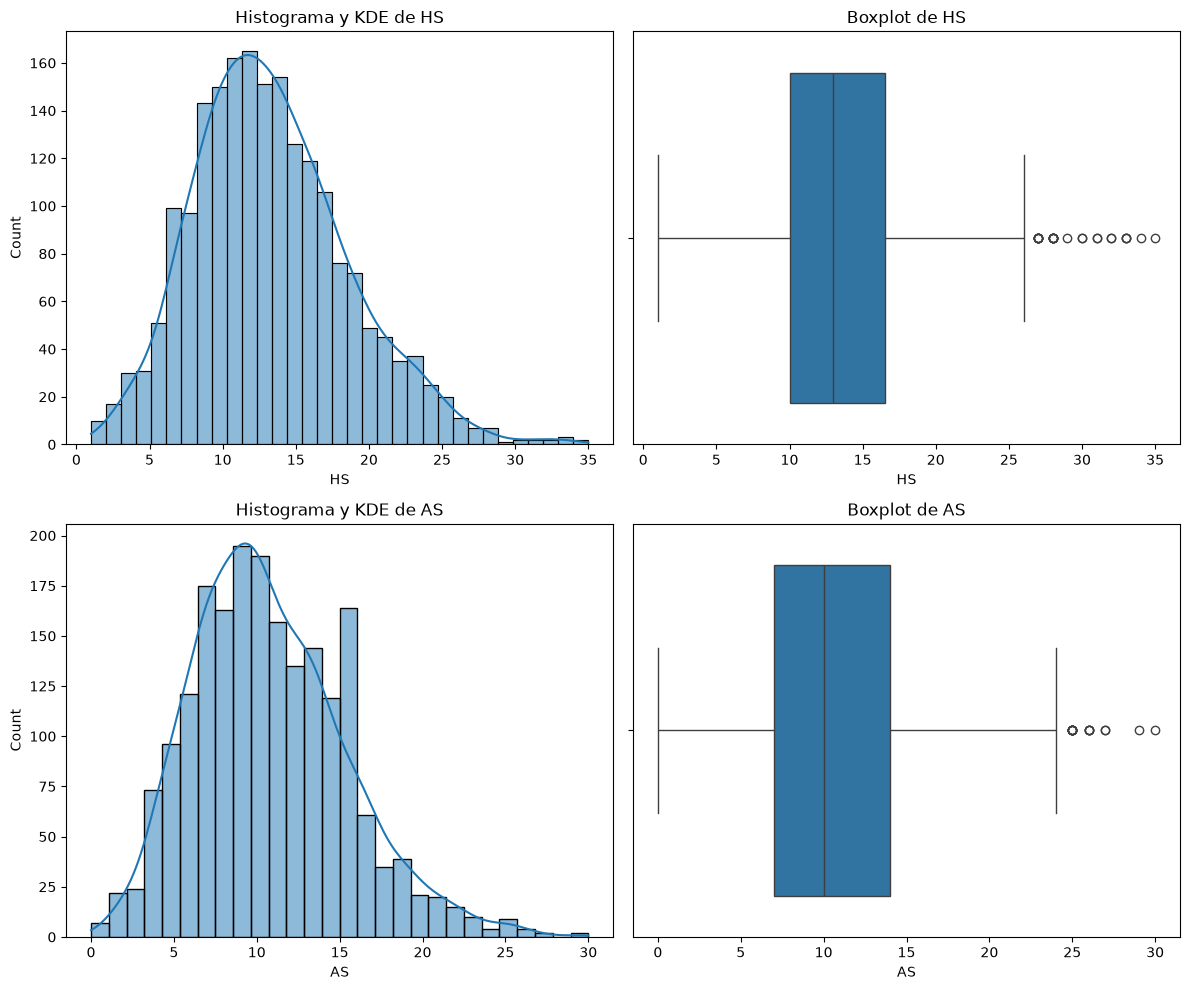

(2, 2)


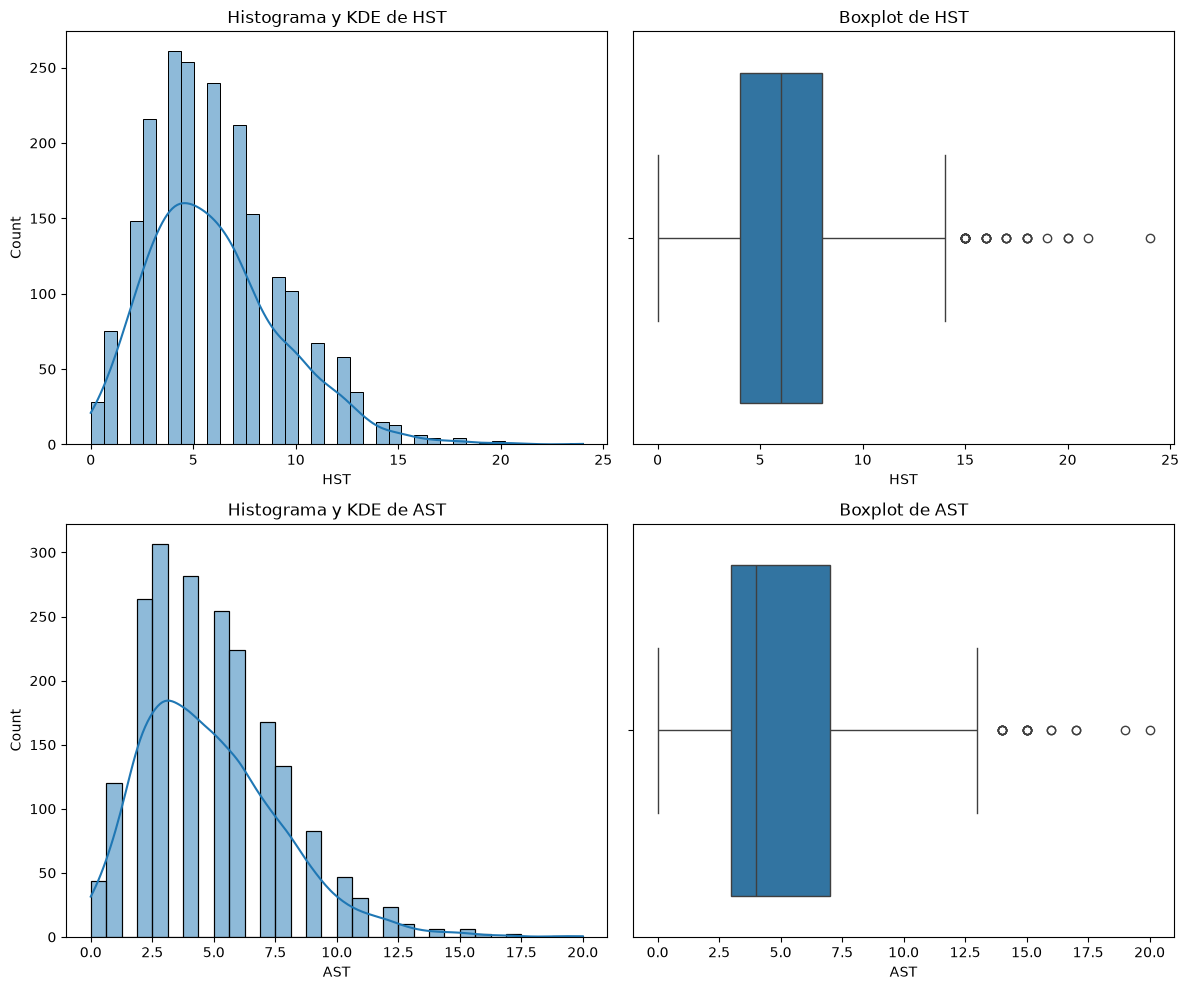

(2, 2)


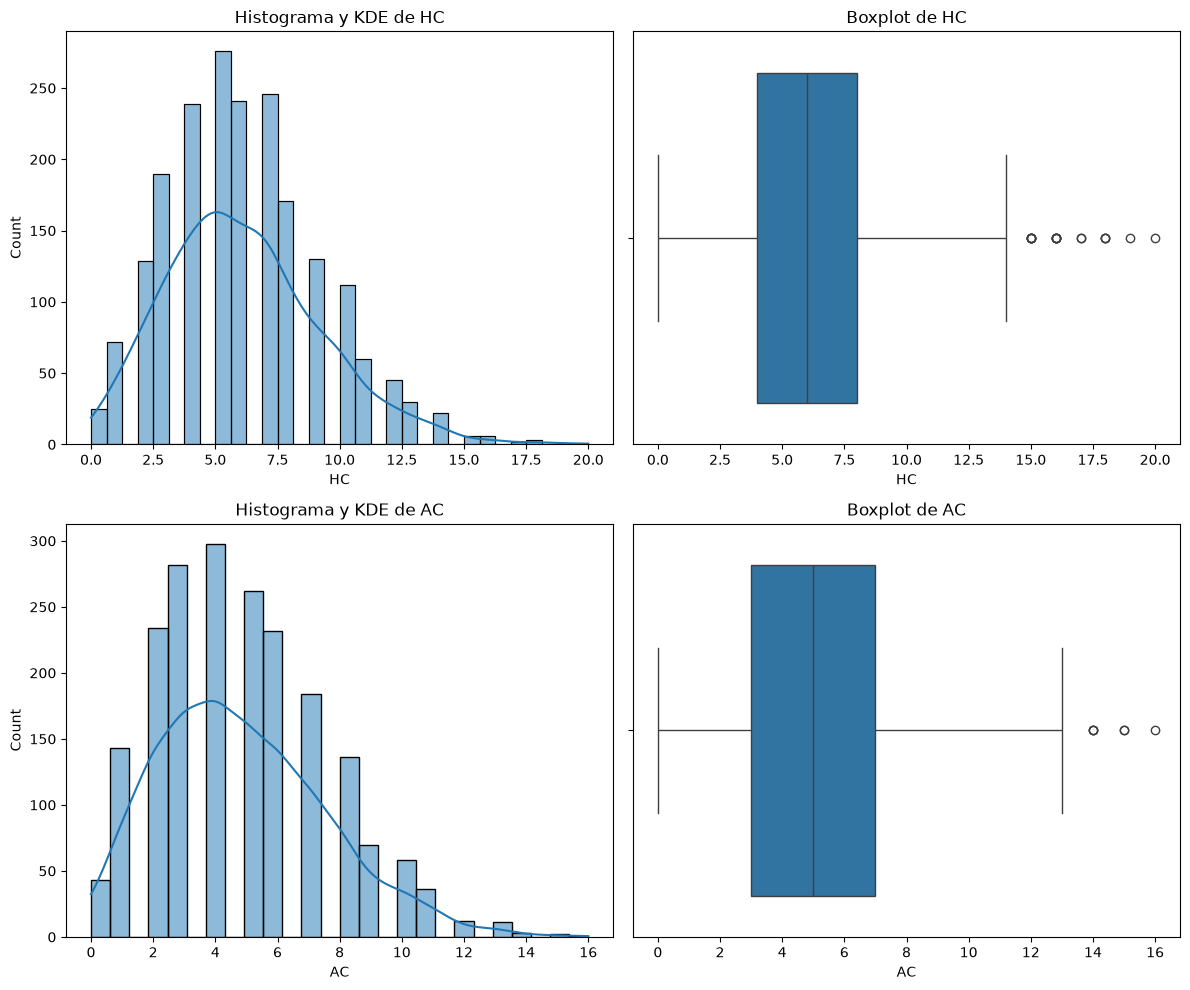

(2, 2)


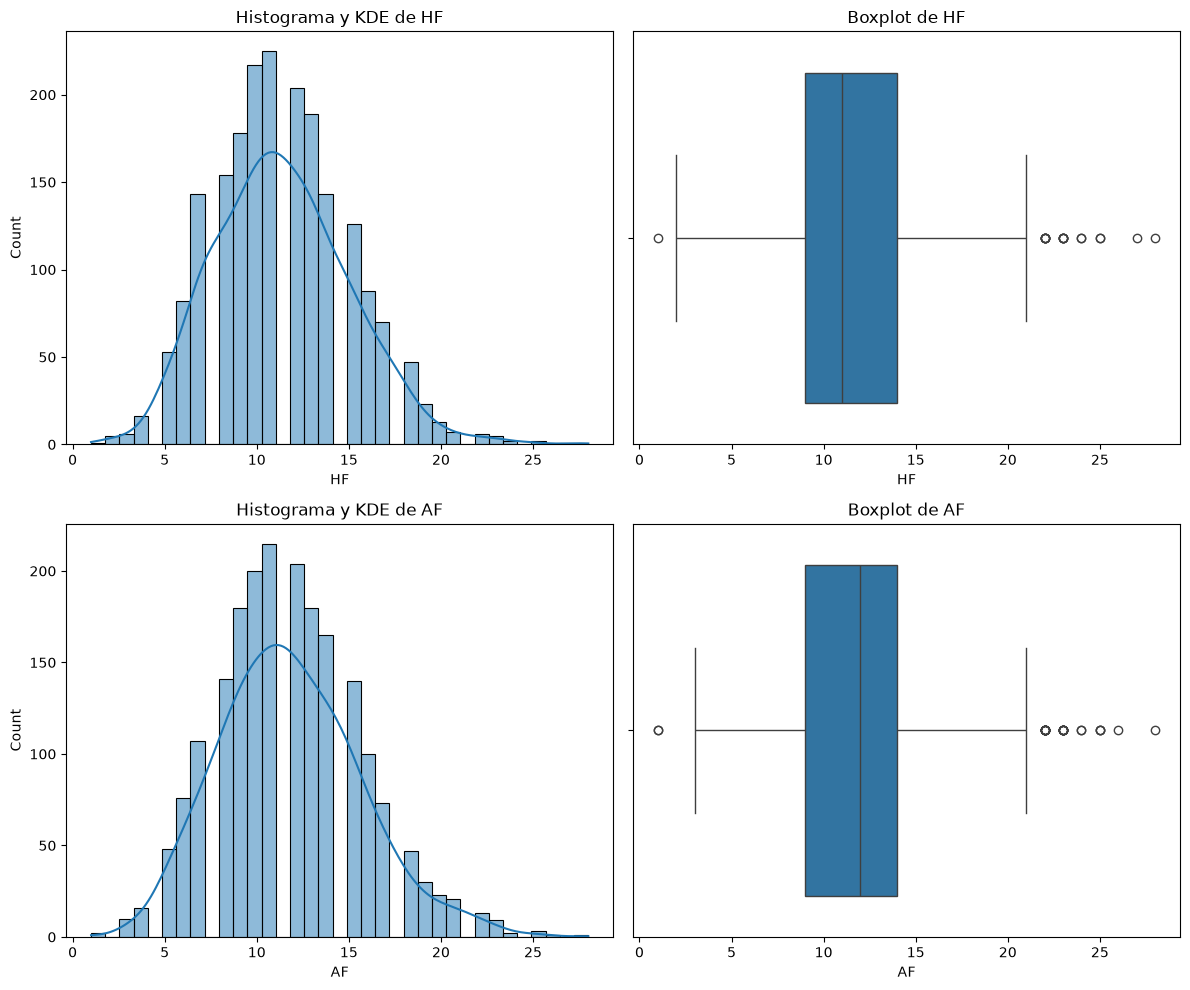

(2, 2)


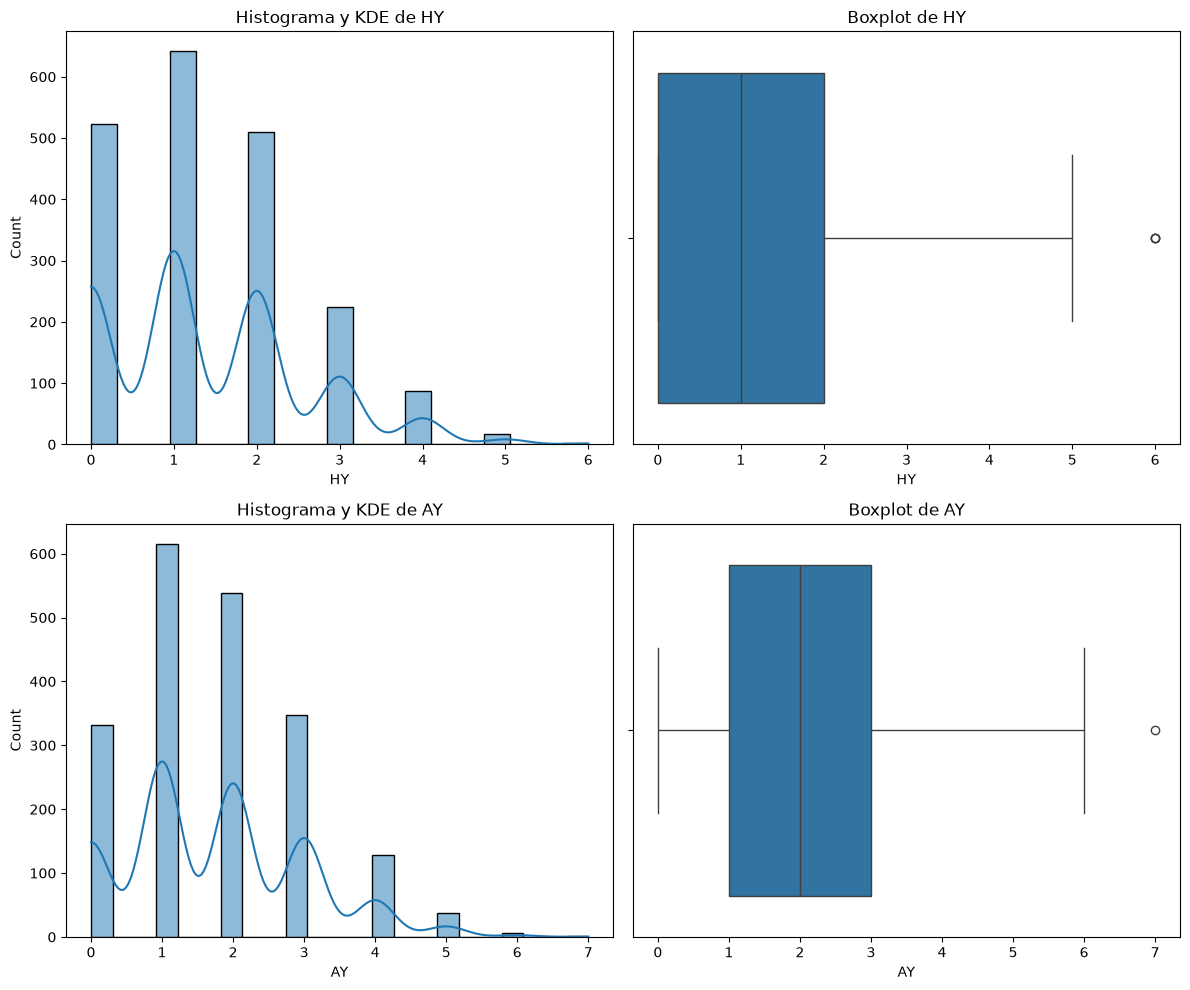

In [77]:
parejas = [("FTHG", "FTAG"), ("HS", "AS"), ("HST", "AST"), ("HC", "AC"), ("HF", "AF"), ("HY", "AY")]

for loc, vis in parejas:
    plot_combined_graphs(df, [loc, vis])

In [78]:
# Las tarjetas rojas son casi siempre 0: el boxplot no sirve, mejor una tabla de frecuencias
pd.concat([df["HR"].value_counts(normalize=True).rename("Rojas local"),
           df["AR"].value_counts(normalize=True).rename("Rojas visitante")], axis=1).round(3)

,Rojas local,Rojas visitante
0.0,0.943,0.905
1.0,0.055,0.091
2.0,0.002,0.004


## Análisis multivariante

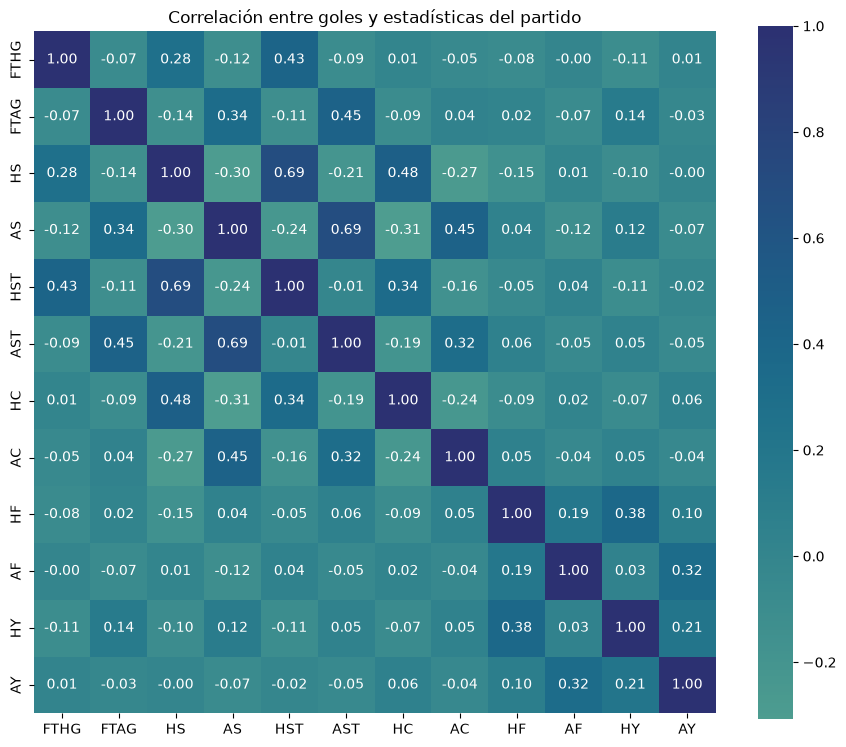

In [79]:
#Estudiamos la correlación entre las distintas estadíticas del partido
columnas_numericas = ["FTHG", "FTAG", "HS", "AS", "HST", "AST", "HC", "AC", "HF", "AF", "HY", "AY"]
plt.figure(figsize=(11, 9))
sns.heatmap(df[columnas_numericas].corr(), annot=True, fmt=".2f", cmap="crest", center=0, square=True)
plt.title("Correlación entre goles y estadísticas del partido")
plt.show()

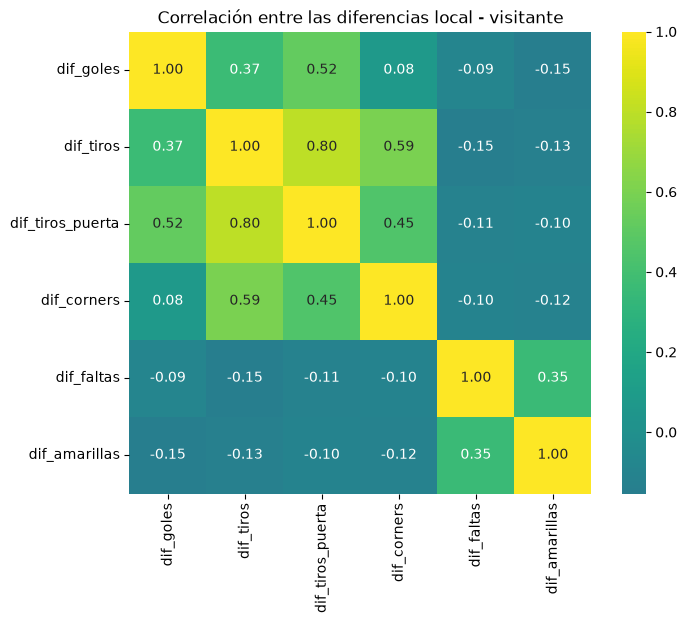

In [80]:
# Lo más útil para la hipótesis: correlaciones entre las diferencias local - visitante
columnas_dif = ["dif_goles", "dif_tiros", "dif_tiros_puerta", "dif_corners", "dif_faltas", "dif_amarillas"]

plt.figure(figsize=(8, 6))
sns.heatmap(df[columnas_dif].corr(), annot=True, fmt=".2f", cmap="viridis", center=0, square=True)
plt.title("Correlación entre las diferencias local - visitante")
plt.show()

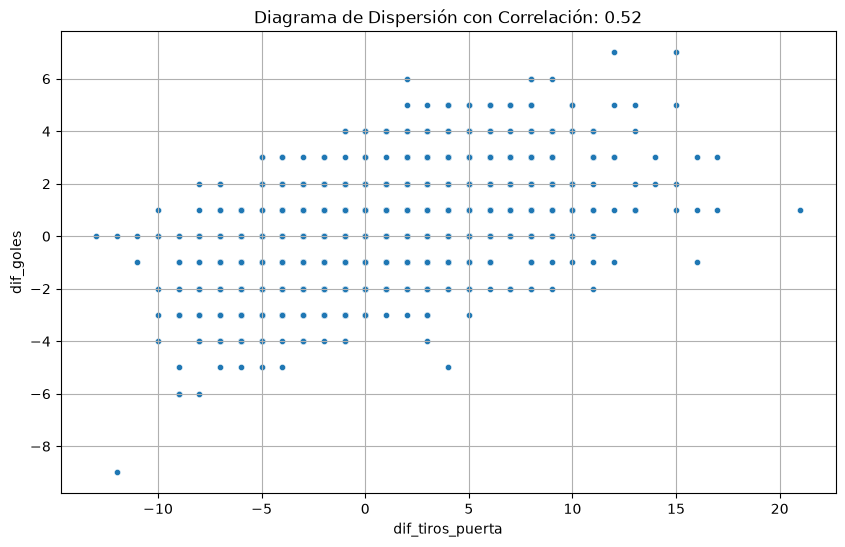

In [87]:
grafico_dispersion_con_correlacion(df, "dif_tiros_puerta", "dif_goles", tamano_puntos=20, mostrar_correlacion=True)

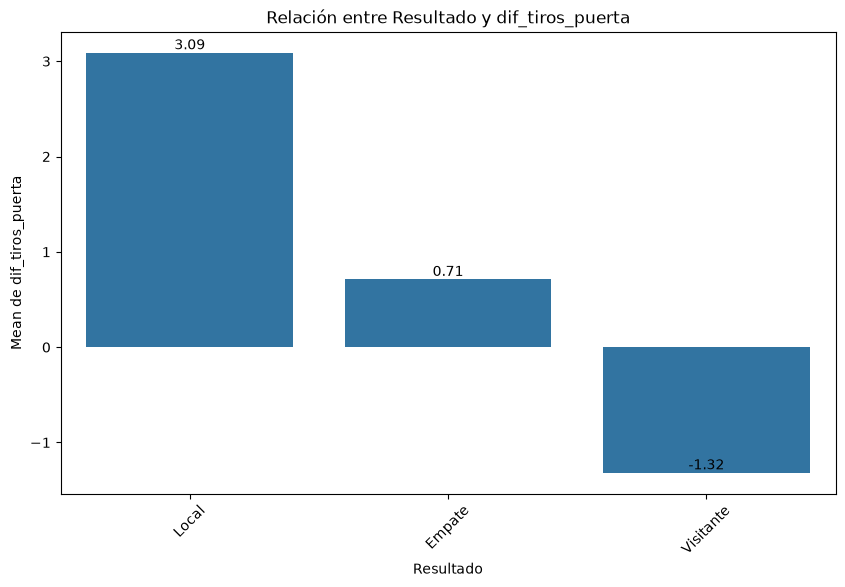

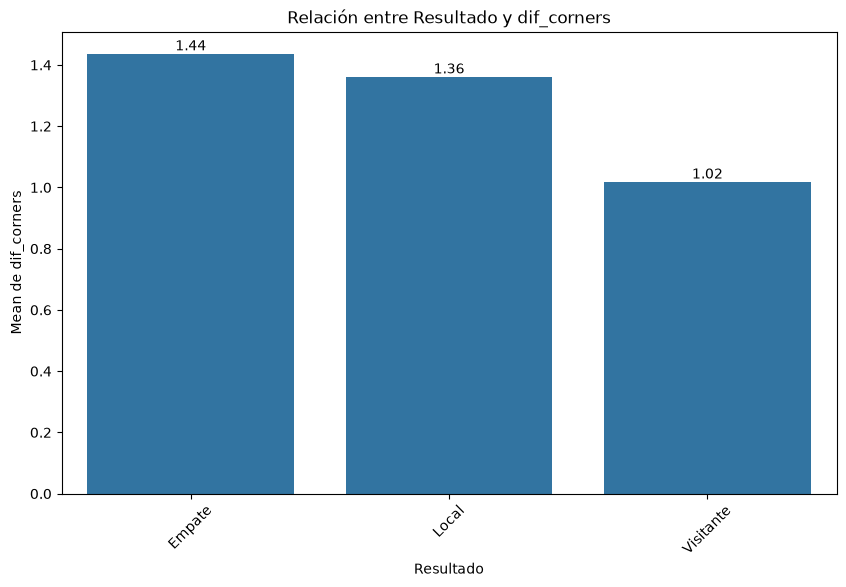

In [88]:
plot_categorical_numerical_relationship(df, "Resultado", "dif_tiros_puerta", show_values=True)
plot_categorical_numerical_relationship(df, "Resultado", "dif_corners", show_values=True)

Cuando gana el local su diferencia media de tiros a puerta es de 3,09, cuando empata de 0,71 y cuando gana el visitante de -1,32.


Ahora voy a reunir las tres diferencias en un solo gráfico, coloreando cada partido por su resultado:

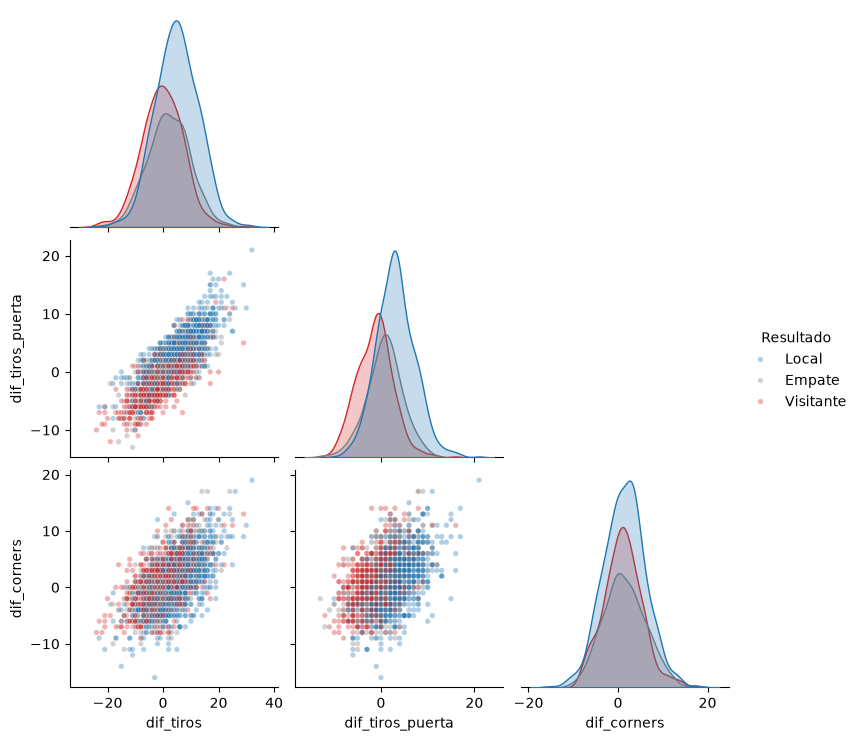

In [97]:
colores = {"Local": "tab:blue", "Empate": "tab:gray", "Visitante": "tab:red"}

sns.pairplot(df, vars=["dif_tiros", "dif_tiros_puerta", "dif_corners"],
             hue="Resultado", hue_order=["Local", "Empate", "Visitante"], palette=colores,
             corner=True, plot_kws={"alpha": 0.35, "s": 15})


Los partidos ganados por el local (azul) se concentran en la zona de diferencias positivas de tiros y tiros a puerta, y los ganados por el visitante (rojo) en la zona negativa.
Con los córneres no hay una separación tan clara.

### Evolución a lo largo de las temporadas

Calculo el porcentaje de victorias locales, empates y victorias visitantes de cada temporada.
Con solo 92 partidos por temporada, cada porcentaje tiene un margen de error de unos 10 puntos (la banda sombreada), así que hay que fijarse en la tendencia y no en cada punto.

In [53]:
por_temporada = df.groupby("año_inicio").agg(
    partidos=("FTR", "size"),
    pct_local=("Local_gana", "mean"),
    pct_empate=("Empate", "mean"),
    pct_visitante=("Visitante_gana", "mean"),
)

por_temporada

,partidos,pct_local,pct_empate,pct_visitante
año_inicio,,,,
2000,92,0.478261,0.282609,0.239130
2001,92,0.434783,0.271739,0.293478
2002,92,0.456522,0.250000,0.293478
2003,92,0.478261,0.315217,0.206522
2004,92,0.445652,0.271739,0.282609
2005,92,0.532609,0.184783,0.282609
2006,92,0.467391,0.260870,0.271739
2007,92,0.456522,0.239130,0.304348
2008,92,0.478261,0.260870,0.260870


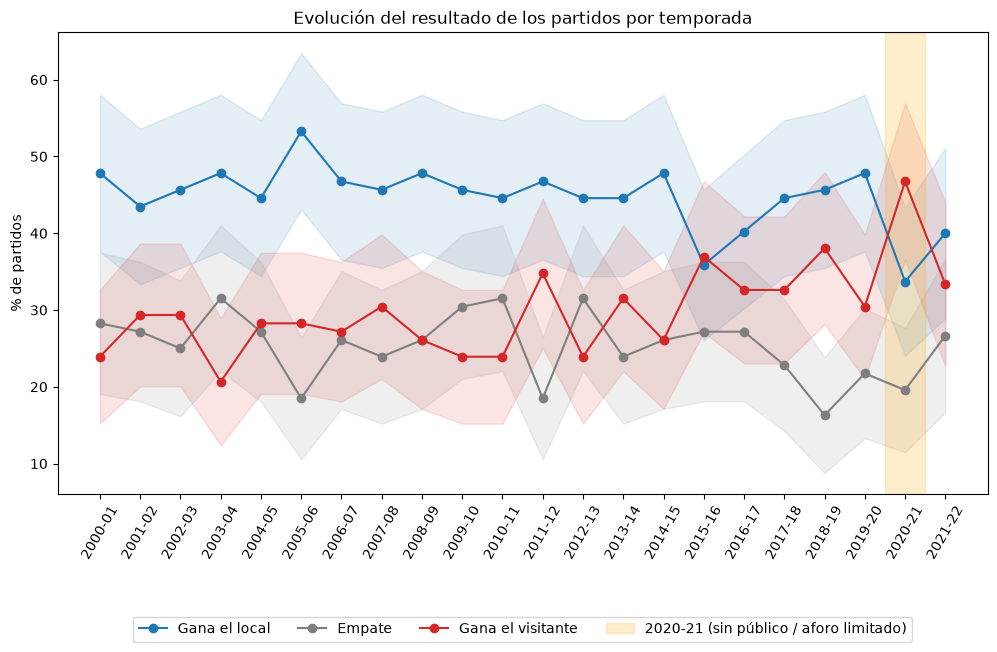

In [54]:
fig, ax = plt.subplots(figsize=(12, 6))
x = por_temporada.index

for col, etiqueta, color in [("pct_local", "Gana el local", "tab:blue"),
                             ("pct_empate", "Empate", "tab:gray"),
                             ("pct_visitante", "Gana el visitante", "tab:red")]:
    p = por_temporada[col]
    error = 1.96 * np.sqrt(p * (1 - p) / por_temporada["partidos"])
    ax.plot(x, p * 100, marker="o", label=etiqueta, color=color)
    ax.fill_between(x, (p - error) * 100, (p + error) * 100, color=color, alpha=0.12)

# Temporada 2020-21: estadios vacíos o con aforo muy limitado por el COVID
ax.axvspan(2019.5, 2020.5, color="orange", alpha=0.2, label="2020-21 (sin público / aforo limitado)")

ax.set_xticks(x)
ax.set_xticklabels([f"{a}-{str(a + 1)[-2:]}" for a in x], rotation=60)
ax.set_ylabel("% de partidos")
ax.set_title("Evolución del resultado de los partidos por temporada")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=4)
plt.show()

Hasta 2014-15 el porcentaje de victorias locales se mueve entre el 43 % y el 53 %. Desde 2015-16 baja a una media del 41 %.
En 2015-16 y en 2020-21 ganan más veces los visitantes que los locales (en 2015-16 por muy poco: 35,9 % frente a 37,0 %).
La temporada 2020-21, con estadios vacíos o con aforo muy limitado por el COVID-19, es la de menor ventaja local de toda la serie: gana el local el 33,7 % de los partidos y el visitante el 46,7 %.
Con 92 partidos por temporada esta diferencia es llamativa pero no concluyente.

Para ver la tendencia de forma más estable agrupo las temporadas en tres periodos.

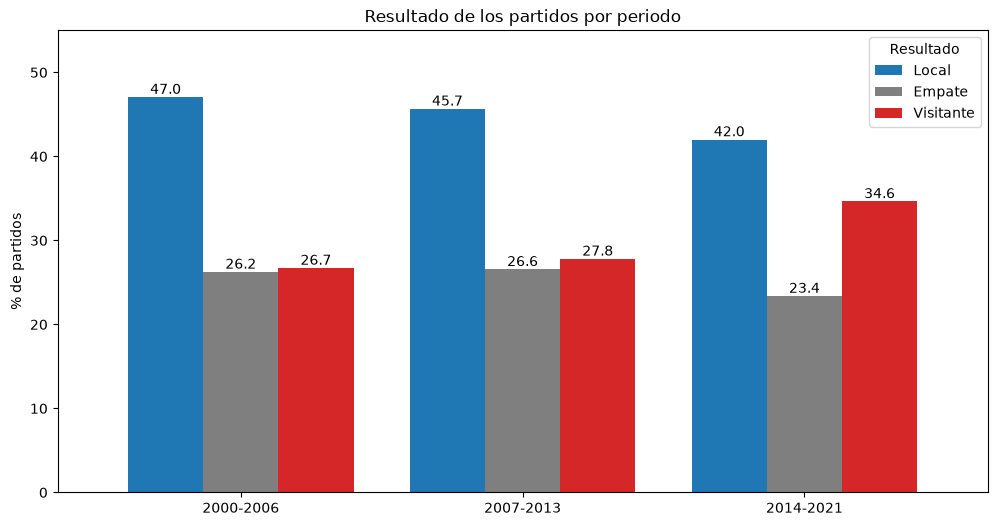

In [55]:
resultado_periodo = pd.crosstab(df["Periodo"], df["Resultado"], normalize="index")[["Local", "Empate", "Visitante"]] * 100

ax = resultado_periodo.plot(kind="bar", figsize=(12, 6), width=0.8, color=["tab:blue", "tab:gray", "tab:red"])
for contenedor in ax.containers:
    ax.bar_label(contenedor, fmt="%.1f", fontsize=10)
ax.set_ylabel("% de partidos")
ax.set_xlabel("")
ax.set_ylim(0, 55)
ax.set_title("Resultado de los partidos por periodo")
plt.xticks(rotation=0)
plt.legend(title="Resultado", loc="upper right")
plt.show()

In [58]:
df.groupby("Periodo").agg(
    partidos=("FTR", "size"),
    goles_local=("FTHG", "mean"),
    goles_visitante=("FTAG", "mean"),
    dif_goles=("dif_goles", "mean"),
    dif_corners=("dif_corners", "mean"),
).round(2)

,partidos,goles_local,goles_visitante,dif_goles,dif_corners
Periodo,,,,,
2000-2006,644,1.47,1.07,0.40,1.36
2007-2013,644,1.52,1.17,0.35,1.35
2014-2021,719,1.45,1.23,0.23,1.13


### PRUEBAS PARA COMPROBAR LA SIGNIFICANCIA ESTADÍSTICA

Realizo una prueba chicuadrado de indepencia para comprobar si hay relación significativa entre jugar en casa y ganar partidos

In [67]:
n = len(df)                                  # 2007 partidos
victorias_local = df["Local_gana"].sum()     # 899
victorias_visitante = df["Visitante_gana"].sum()   # 600

tabla = pd.DataFrame({
    "Gana": [victorias_local, victorias_visitante],
    "No gana": [n - victorias_local, n - victorias_visitante],
}, index=["Local", "Visitante"])

tabla

,Gana,No gana
Local,899,1108
Visitante,600,1407


In [70]:
chi2, p_valor, grados_libertad, esperados = stats.chi2_contingency(tabla)

print(f"Chi-cuadrado: {chi2:.1f}")
print(f"p-valor: {p_valor:.2e}")
print(esperados.round(1))

Chi-cuadrado: 94.6
p-valor: 2.39e-22
[[ 749.5 1257.5]
 [ 749.5 1257.5]]


Chi-cuadrado de independencia (el que preguntabas)
**H0 (nula):** jugar de local no se relaciona con ganar. La proporción de victorias es la misma de local que de visitante.
**H1 (alternativa):** jugar de local sí se relaciona con ganar. La proporción de victorias es distinta.

Con un p-valor de 2 · 10⁻²² (muy por debajo de 0,05) rechazo H0 y me quedo con H1.
El p-valor dice que hay relación, pero no cuánta. Para el tamaño del efecto, añade:

In [71]:
tasa_local = victorias_local / n
tasa_visitante = victorias_visitante / n
print(f"Gana el {tasa_local:.1%} como local y el {tasa_visitante:.1%} como visitante")
print(f"Diferencia: {(tasa_local - tasa_visitante) * 100:.1f} puntos")

# Odds ratio: cuántas veces más probable es ganar de local
odds_ratio = (victorias_local / (n - victorias_local)) / (victorias_visitante / (n - victorias_visitante))
print(f"Odds ratio: {odds_ratio:.2f}")

Gana el 44.8% como local y el 29.9% como visitante
Diferencia: 14.9 puntos
Odds ratio: 1.90


Las odds son la relación entre ganar y no ganar:

Local: 899 / 1108 = 0,81. Por cada 100 partidos en que no gana, gana 81.
Visitante: 600 / 1407 = 0,43. Por cada 100 en que no gana, gana 43.

El odds ratio es el cociente: 0,81 / 0,43 = 1,9. Las odds de ganar de local son 1,9 veces las de ganar de visitante, es decir, casi el doble.

La comparación que se entiende mejor es esta:

44,8 % / 29,9 % = 1,5. El local gana un 50 % más de partidos que el visitante.